# Regional Wind Resource Mapping using the NSF NCAR ERA5 Dataset

This notebook demonstrates how to access and spatially subset the **NSF NCAR Curated ERA5** dataset in the AWS Open Data Registry, using 100 m wind fields over Texas and the US South-Central region.

## Demonstration workflow
- Access monthly NetCDF4 files anonymously from the public `nsf-ncar-era5` S3 bucket
- Select a geographic region before loading data into memory
- Derive mean wind speed and reference-density wind power density
- Calculate an **illustrative normalized output factor** with a generic power curve
- Optionally compare the highest-resource grid cells for the selected period

> **Scope:** The default one-month run is intentionally small enough for a sample notebook. It demonstrates data access and spatial comparison; it is **not** a climatology, site assessment, or estimate of bankable energy production.

## Why this dataset fits the demonstration
The selected NCAR ERA5 surface-analysis files are monthly global grids. This layout is useful for regional analysis because one pair of U/V files covers every grid cell in the area of interest. Selecting the region before `.load()` avoids loading the full global arrays into memory, although remote transfer performance still depends on NetCDF/HDF5 chunking and cache behavior.

## Dataset
The [NSF NCAR Curated ERA5](https://registry.opendata.aws/nsf-ncar-era5/) collection is provided in CF-compliant NetCDF4 format in the public `nsf-ncar-era5` bucket in `us-west-2`.

| S3 parameter code | Description |
|---|---|
| `228_246_100u` | 100 m U-component of wind (m/s) |
| `228_247_100v` | 100 m V-component of wind (m/s) |

No AWS account or credentials are required.

### Citation
NSF NCAR Curated ECMWF Reanalysis 5 (ERA5), accessed 2026-07-15 from https://registry.opendata.aws/nsf-ncar-era5/. European Centre for Medium-Range Weather Forecasts. 2019, updated monthly. *ERA5 Reanalysis (0.25 Degree Latitude-Longitude Grid).* Research Data Archive at NSF NCAR/CISL. https://doi.org/10.5065/BH6N-5N20


In [37]:
# Install dependencies when running in a fresh environment (e.g., a SageMaker notebook instance).
# --only-binary=:all: forces pip to use pre-built wheels for the current platform instead of
# compiling from source, which fails on Amazon Linux 2 (GCC 7.3 < 10.3 required by NumPy,
# and no PROJ library available for pyproj/cartopy).
# !pip install --only-binary=:all: s3fs==0.4.2 xarray h5netcdf h5py numpy matplotlib -q
# Optional geographic context map and land/sea classification:
# !pip install --only-binary=:all: cartopy global-land-mask -q


In [38]:
import calendar
import time

import matplotlib.pyplot as plt
import numpy as np
import s3fs
import xarray as xr
from IPython.display import Markdown, display


## 1. Configuration

Define the region and explicit `(year, month)` pairs to analyze.

The default uses one month so the sample remains practical to run from a laptop. Its results describe **only that selected month**. For seasonal comparisons, add the appropriate year/month pairs; for resource assessment, use complete years and preferably a multi-year period.

> **Performance note:** These are large global NetCDF/HDF5 files. Regional selection reduces the in-memory array, but transferred bytes and speed depend on file chunking, caching, and network location. Running in `us-west-2` generally reduces network latency; remote HDF5 access can still take time.


In [39]:
# Region of interest: Texas and the US South-Central region
LAT_MIN, LAT_MAX = 25.0, 37.0
LON_MIN, LON_MAX = -107.0, -93.0
REGION_NAME = "Texas & US South-Central"

# Explicit pairs correctly represent periods that cross calendar years.
YEAR_MONTHS = [(2024, 1)]
# Example DJF season: [(2023, 12), (2024, 1), (2024, 2)]
YEAR_MONTHS = list(dict.fromkeys(YEAR_MONTHS))

if not YEAR_MONTHS:
    raise ValueError("YEAR_MONTHS must contain at least one (year, month) pair")
if any(not 1 <= month <= 12 for _, month in YEAR_MONTHS):
    raise ValueError("Every month in YEAR_MONTHS must be between 1 and 12")
if not (-90 <= LAT_MIN < LAT_MAX <= 90):
    raise ValueError("Latitude bounds must satisfy -90 <= LAT_MIN < LAT_MAX <= 90")
if not (-180 <= LON_MIN < LON_MAX <= 180):
    raise ValueError("This sample expects a non-antimeridian-crossing longitude box")

# Generic normalized-output curve and reference-density WPD assumptions
CUT_IN, RATED_SPEED, CUT_OUT = 3.5, 12.0, 25.0
REFERENCE_AIR_DENSITY = 1.225  # kg/m³; standard sea-level reference value

# Anonymous AWS access
BUCKET = "nsf-ncar-era5"
S3_REGION = "us-west-2"
fs = s3fs.S3FileSystem(
    anon=True,
    client_kwargs={"region_name": S3_REGION},
)


### 1.1 Geographic Context of the Analysis Box

This optional map draws the complete rectangular bounding box selected above. It shows why the example includes parts of **New Mexico, Mexico, and the Gulf of Mexico**, in addition to Texas. The orange rectangle represents every ERA5 grid cell considered; it is not the boundary of Texas.


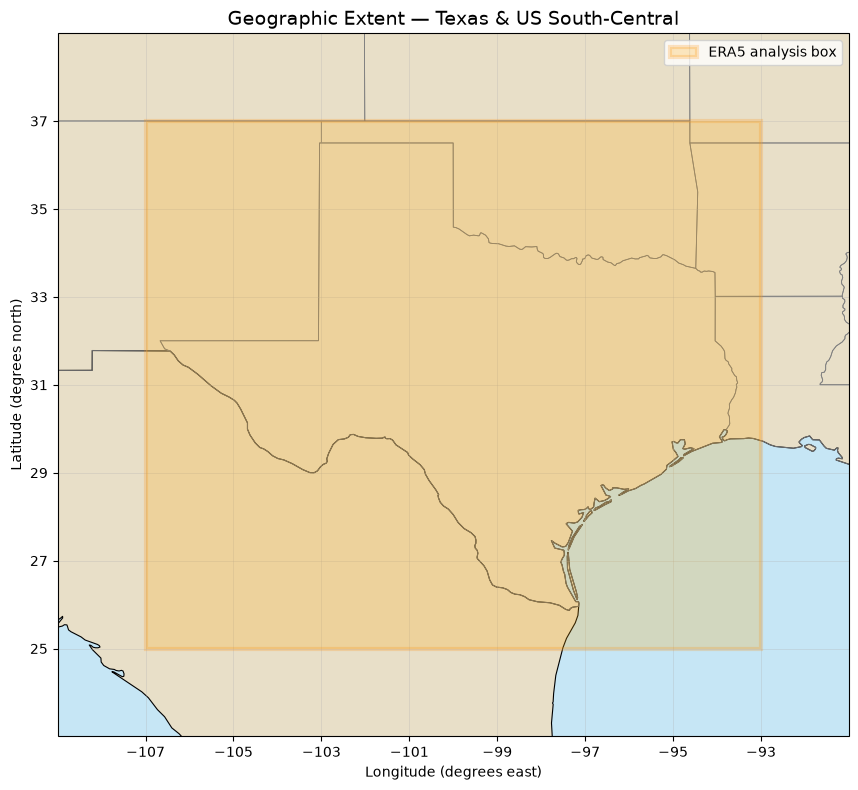

In [40]:
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    from matplotlib.patches import Rectangle
except ImportError:
    display(Markdown(
        "Install `cartopy==0.25.0` to display the optional geographic context map."
    ))
else:
    projection = ccrs.PlateCarree()
    fig, ax = plt.subplots(
        figsize=(10, 8),
        subplot_kw={"projection": projection},
    )
    ax.set_extent(
        [LON_MIN - 2, LON_MAX + 2, LAT_MIN - 2, LAT_MAX + 2],
        crs=projection,
    )
    ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#e8dfc8")
    ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#c6e6f5")
    ax.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.8)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.8)
    ax.add_feature(cfeature.STATES.with_scale("50m"), linewidth=0.6, edgecolor="gray")

    analysis_box = Rectangle(
        (LON_MIN, LAT_MIN),
        LON_MAX - LON_MIN,
        LAT_MAX - LAT_MIN,
        transform=projection,
        facecolor="orange",
        edgecolor="darkorange",
        linewidth=3,
        alpha=0.22,
        zorder=4,
        label="ERA5 analysis box",
    )
    ax.add_patch(analysis_box)
    ax.set_xticks(
        np.arange(np.floor(LON_MIN), np.ceil(LON_MAX) + 1, 2),
        crs=projection,
    )
    ax.set_yticks(
        np.arange(np.floor(LAT_MIN), np.ceil(LAT_MAX) + 1, 2),
        crs=projection,
    )
    ax.grid(linewidth=0.4, alpha=0.5)
    ax.set_xlabel("Longitude (degrees east)")
    ax.set_ylabel("Latitude (degrees north)")
    ax.set_title(f"Geographic Extent — {REGION_NAME}", fontsize=14)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


## 2. Discover and Load the Regional Wind Fields

The surface-analysis files used here follow this layout:

```text
s3://nsf-ncar-era5/e5.oper.an.sfc/YYYYMM/e5.oper.an.sfc.<parameter>.<...>.nc
```

For each requested month, the loader:

1. Deterministically identifies exactly one U or V object.
2. Prints the selected S3 key and variable metadata.
3. Validates dimensions before selecting the region.
4. Loads the regional subset and closes the remote file.
5. Verifies that the combined U/V arrays are exactly aligned and hourly.

ERA5 longitude is stored from 0–360° and latitude is descending from 90°N to 90°S. This concise sample supports ordinary longitude boxes only; a region crossing the antimeridian requires two longitude slices.


In [21]:
VAR_CODES = {
    "100u": "228_246_100u",
    "100v": "228_247_100v",
}
REQUIRED_DIMS = {"time", "latitude", "longitude"}


def load_region(parameter_code, year, month):
    '''Load one validated monthly parameter field for the selected region.'''
    prefix = f"{BUCKET}/e5.oper.an.sfc/{year:04d}{month:02d}/"
    matches = sorted(
        key for key in fs.ls(prefix)
        if f"an.sfc.{parameter_code}." in key
    )
    if len(matches) != 1:
        raise RuntimeError(
            f"Expected exactly one file for {parameter_code} in "
            f"{year}-{month:02d}; found {len(matches)}: {matches}"
        )

    path = matches[0]
    print(f"  Opening s3://{path}")

    # Readahead combines many nearby remote reads; effectiveness depends on file chunking.
    with fs.open(path, "rb", cache_type="readahead") as remote_file:
        with xr.open_dataset(remote_file, engine="h5netcdf") as dataset:
            candidates = [
                name for name, array in dataset.data_vars.items()
                if REQUIRED_DIMS.issubset(array.dims)
            ]
            if len(candidates) != 1:
                raise RuntimeError(
                    f"Expected exactly one gridded time-varying variable in {path}; "
                    f"found {candidates}"
                )

            variable_name = candidates[0]
            source = dataset[variable_name]
            units = source.attrs.get("units", "not provided")
            long_name = source.attrs.get("long_name", "not provided")
            print(
                f"    Variable: {variable_name} | units: {units} | "
                f"long_name: {long_name} | dims: {dict(source.sizes)}"
            )

            regional = source.sel(
                latitude=slice(LAT_MAX, LAT_MIN),
                longitude=slice(LON_MIN % 360, LON_MAX % 360),
            ).load()

    if regional.sizes["latitude"] == 0 or regional.sizes["longitude"] == 0:
        raise ValueError("The requested bounding box selected no grid cells")
    return regional


period_label = ", ".join(f"{year}-{month:02d}" for year, month in YEAR_MONTHS)
print(f"Loading 100 m wind for {REGION_NAME}")
print(f"Box: lat [{LAT_MIN}, {LAT_MAX}], lon [{LON_MIN}, {LON_MAX}]")
print(f"Months: {period_label}")

u_parts, v_parts = [], []
total_start = time.time()
for year, month in YEAR_MONTHS:
    month_start = time.time()
    u_parts.append(load_region(VAR_CODES["100u"], year, month))
    v_parts.append(load_region(VAR_CODES["100v"], year, month))
    print(f"  {year}-{month:02d} loaded in {time.time() - month_start:.0f}s")

u = xr.concat(u_parts, dim="time").sortby("time")
v = xr.concat(v_parts, dim="time").sortby("time")

# Convert longitude back to -180..180 and restore monotonic ordering.
u = u.assign_coords(
    longitude=((u.longitude + 180) % 360) - 180
).sortby("longitude")
v = v.assign_coords(
    longitude=((v.longitude + 180) % 360) - 180
).sortby("longitude")

# Exact alignment prevents silent arithmetic across mismatched grids or timestamps.
u, v = xr.align(u, v, join="exact")

for component_name, component in {"u": u, "v": v}.items():
    time_index = component.indexes["time"]
    if not time_index.is_monotonic_increasing or not time_index.is_unique:
        raise ValueError(f"{component_name} timestamps are not sorted and unique")
    if bool(component.isnull().any().item()):
        raise ValueError(f"{component_name} contains missing values in the selected region")

expected_hours = sum(
    calendar.monthrange(year, month)[1] * 24
    for year, month in YEAR_MONTHS
)
if u.sizes["time"] != expected_hours:
    raise ValueError(
        f"Expected {expected_hours} hourly records, found {u.sizes['time']}"
    )

if u.sizes["time"] > 1:
    time_steps = np.diff(u.time.values)
    if not np.all(time_steps == np.timedelta64(1, "h")):
        raise ValueError("The combined time coordinate is not continuously hourly")

print(
    f"\nLoaded grid: {u.sizes['latitude']} lat × {u.sizes['longitude']} lon "
    f"× {u.sizes['time']} hourly steps in {time.time() - total_start:.0f}s"
)
print(f"Time range: {u.time.values[0]} to {u.time.values[-1]}")
print(
    f"Coordinate ranges: latitude {float(u.latitude.min()):.2f} to "
    f"{float(u.latitude.max()):.2f}; longitude {float(u.longitude.min()):.2f} "
    f"to {float(u.longitude.max()):.2f}"
)


Loading 100 m wind for Texas & US South-Central
Box: lat [25.0, 37.0], lon [-107.0, -93.0]
Months: 2024-01
  Opening s3://nsf-ncar-era5/e5.oper.an.sfc/202401/e5.oper.an.sfc.228_246_100u.ll025sc.2024010100_2024013123.nc
    Variable: VAR_100U | units: m s**-1 | long_name: 100 metre U wind component | dims: {'time': 744, 'latitude': 721, 'longitude': 1440}
  Opening s3://nsf-ncar-era5/e5.oper.an.sfc/202401/e5.oper.an.sfc.228_247_100v.ll025sc.2024010100_2024013123.nc
    Variable: VAR_100V | units: m s**-1 | long_name: 100 metre V wind component | dims: {'time': 744, 'latitude': 721, 'longitude': 1440}
  2024-01 loaded in 74s

Loaded grid: 49 lat × 57 lon × 744 hourly steps in 74s
Time range: 2024-01-01T00:00:00.000000000 to 2024-01-31T23:00:00.000000000
Coordinate ranges: latitude 25.00 to 37.00; longitude -107.00 to -93.00


## 3. Compute Demonstration-Period Wind Metrics

From the hourly U/V fields, derive three spatial metrics:

| Metric | Formula | Interpretation |
|---|---|---|
| Mean wind speed | $\overline{\sqrt{u^2+v^2}}$ | Mean 100 m grid-scale wind speed for the selected period |
| Reference-density WPD | $\tfrac{1}{2}\rho_0\,\overline{v^3}$ | Comparative wind power density using $\rho_0=1.225$ kg/m³ |
| Illustrative output factor | $\overline{f(v)}$ | Normalized output from a generic cubic-ramp curve |

Wind power density correctly uses the **mean of cubed hourly speed**, rather than the cube of mean speed. The output factor is not turbine-specific capacity factor and excludes density effects, wakes, availability, electrical losses, and controls.


In [22]:
# Hourly scalar 100 m wind speed at every grid cell
speed = np.hypot(u, v)
speed.name = "wind_speed_100m"

mean_speed = speed.mean(dim="time")
mean_speed.name = "mean_wind_speed"

# Comparative WPD at a fixed standard reference density.
power_density = (
    0.5 * REFERENCE_AIR_DENSITY * (speed ** 3).mean(dim="time")
)
power_density.name = "reference_density_wind_power_density"


def illustrative_output(ws):
    '''Return normalized output (0–1) from a generic cubic-ramp curve.'''
    ramp = ((ws - CUT_IN) / (RATED_SPEED - CUT_IN)) ** 3
    return xr.where(
        (ws >= CUT_IN) & (ws < RATED_SPEED),
        ramp,
        xr.where((ws >= RATED_SPEED) & (ws < CUT_OUT), 1.0, 0.0),
    )


output_factor = illustrative_output(speed).mean(dim="time")
output_factor.name = "illustrative_output_factor"

print("Selected-period grid-cell ranges:")
print(
    f"  Mean wind speed: {float(mean_speed.min()):.1f}–"
    f"{float(mean_speed.max()):.1f} m/s"
)
print(
    f"  Reference-density WPD: {float(power_density.min()):.0f}–"
    f"{float(power_density.max()):.0f} W/m²"
)
print(
    f"  Illustrative output factor: {float(output_factor.min()) * 100:.0f}–"
    f"{float(output_factor.max()) * 100:.0f}%"
)


Selected-period grid-cell ranges:
  Mean wind speed: 1.7–9.3 m/s
  Reference-density WPD: 7–856 W/m²
  Illustrative output factor: 0–42%


## 4. Map the Selected-Period Metrics

These dependency-light latitude/longitude heatmaps show spatial differences during the selected demonstration period. They are not siting maps; coastlines and administrative boundaries are intentionally omitted from the minimal workflow.


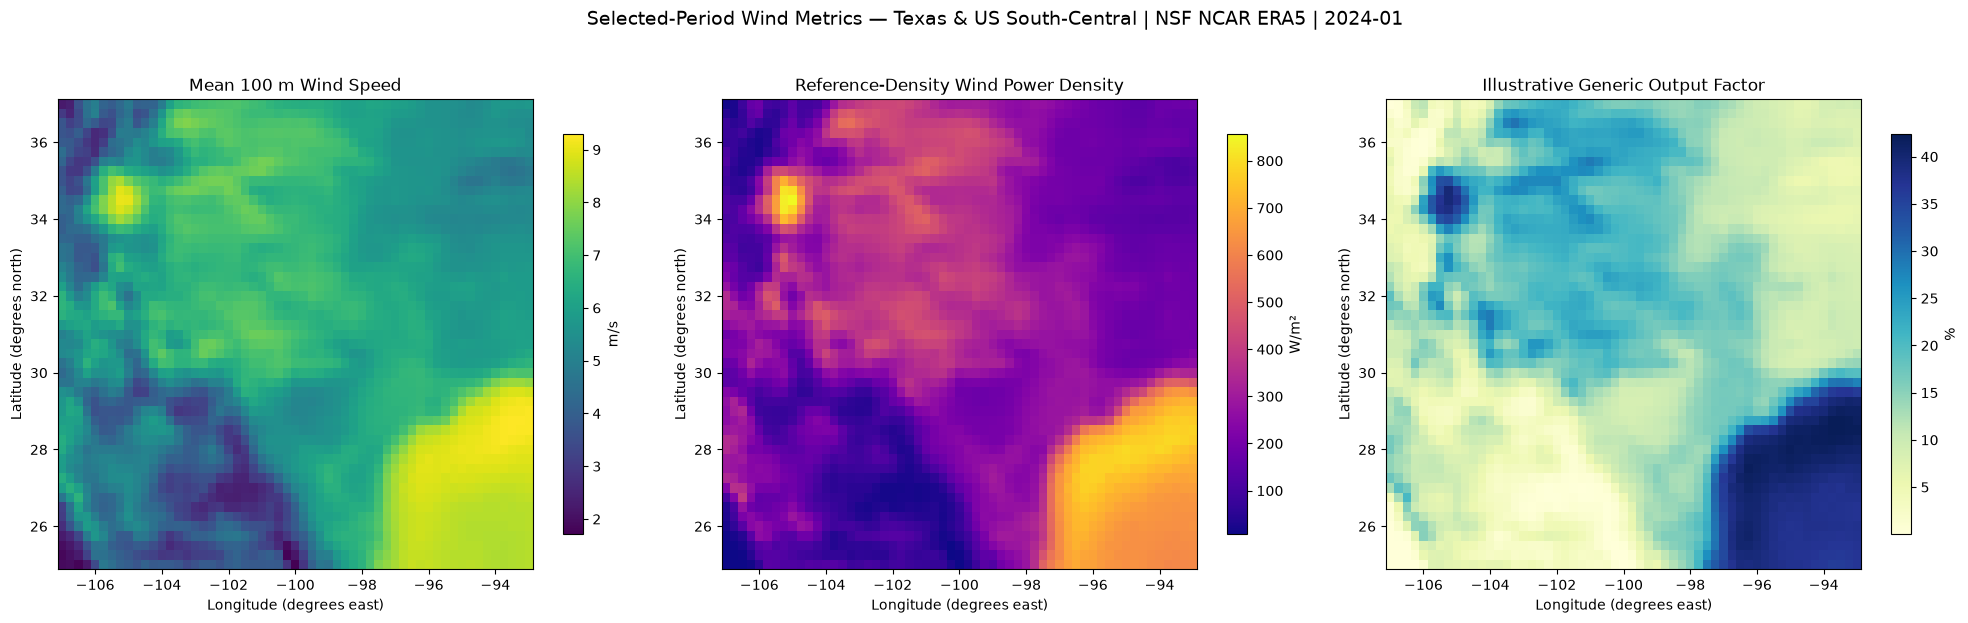

In [23]:
def plot_field(ax, field, title, cmap, colorbar_label):
    '''Draw a latitude/longitude field as a dependency-light heatmap.'''
    mesh = ax.pcolormesh(
        field.longitude,
        field.latitude,
        field.values,
        cmap=cmap,
        shading="auto",
    )
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Longitude (degrees east)")
    ax.set_ylabel("Latitude (degrees north)")
    colorbar = plt.colorbar(mesh, ax=ax, shrink=0.85)
    colorbar.set_label(colorbar_label)


fig, axes = plt.subplots(1, 3, figsize=(20, 6))
plot_field(
    axes[0], mean_speed,
    "Mean 100 m Wind Speed", "viridis", "m/s",
)
plot_field(
    axes[1], power_density,
    "Reference-Density Wind Power Density", "plasma", "W/m²",
)
plot_field(
    axes[2], output_factor * 100,
    "Illustrative Generic Output Factor", "YlGnBu", "%",
)
fig.suptitle(
    f"Selected-Period Wind Metrics — {REGION_NAME} | "
    f"NSF NCAR ERA5 | {period_label}",
    fontsize=14,
    y=1.03,
)
plt.tight_layout()
plt.show()


## 5. Optional Grid-Cell Comparison

The following optional section lists the cells with the highest **illustrative output factor during the selected period**. This is a spatial comparison—not a shortlist of viable wind-farm sites.

A grid cell is approximately 0.25° and can contain mixed land, water, terrain, and land uses. The optional land mask classifies only the cell center; it does not represent the full cell or account for development constraints, transmission, ownership, setbacks, bathymetry, wakes, or local terrain.


In [24]:
try:
    from global_land_mask import globe

    def is_land(latitude, longitude):
        return bool(globe.is_land(latitude, longitude))

    land_mask_available = True
except ImportError:
    def is_land(latitude, longitude):
        return None

    land_mask_available = False
    print(
        "[optional] Install global-land-mask==1.0.0 to classify grid centers "
        "as land or sea."
    )


def land_sea_label(latitude, longitude):
    value = is_land(latitude, longitude)
    if value is True:
        return "Land center"
    if value is False:
        return "Sea center"
    return "Not classified"


ranked_output = output_factor.stack(
    cell=("latitude", "longitude")
).sortby(output_factor.stack(cell=("latitude", "longitude")), ascending=False)

top_n = min(10, ranked_output.sizes["cell"])
print(f"Top {top_n} grid cells for {period_label}:\n")
print(
    f"{'Rank':>4}  {'Lat':>7}  {'Lon':>8}  {'Output %':>8}  "
    f"{'Mean m/s':>9}  {'WPD W/m²':>9}  {'Center class':>14}"
)
print("-" * 82)

for rank in range(top_n):
    latitude = float(ranked_output.latitude[rank])
    longitude = float(ranked_output.longitude[rank])
    output_percent = float(ranked_output[rank]) * 100
    mean_ws = float(mean_speed.sel(latitude=latitude, longitude=longitude))
    wpd = float(power_density.sel(latitude=latitude, longitude=longitude))
    center_class = land_sea_label(latitude, longitude)
    print(
        f"{rank + 1:>4}  {latitude:>7.2f}  {longitude:>8.2f}  "
        f"{output_percent:>8.1f}  {mean_ws:>9.2f}  {wpd:>9.0f}  "
        f"{center_class:>14}"
    )

highest_latitude = float(ranked_output.latitude[0])
highest_longitude = float(ranked_output.longitude[0])
print("\n" + "=" * 82)
print(
    f"Highest selected-period output cell: {highest_latitude:.2f}°, "
    f"{highest_longitude:.2f}° — "
    f"{land_sea_label(highest_latitude, highest_longitude)}"
)

if land_mask_available:
    highest_land = None
    highest_sea = None
    for index in range(ranked_output.sizes["cell"]):
        latitude = float(ranked_output.latitude[index])
        longitude = float(ranked_output.longitude[index])
        output_percent = float(ranked_output[index]) * 100
        center_is_land = is_land(latitude, longitude)
        if highest_land is None and center_is_land:
            highest_land = (latitude, longitude, output_percent)
        if highest_sea is None and not center_is_land:
            highest_sea = (latitude, longitude, output_percent)
        if highest_land and highest_sea:
            break

    if highest_land:
        print(
            f"Highest land-center cell: {highest_land[0]:.2f}°, "
            f"{highest_land[1]:.2f}° | output factor {highest_land[2]:.1f}%"
        )
    if highest_sea:
        print(
            f"Highest sea-center cell: {highest_sea[0]:.2f}°, "
            f"{highest_sea[1]:.2f}° | output factor {highest_sea[2]:.1f}%"
        )
print("=" * 82)


Top 10 grid cells for 2024-01:

Rank      Lat       Lon  Output %   Mean m/s   WPD W/m²    Center class
----------------------------------------------------------------------------------
   1    28.50    -93.75      42.4       9.26        778      Sea center
   2    28.75    -93.75      42.3       9.26        768      Sea center
   3    28.50    -93.50      42.3       9.26        777      Sea center
   4    28.75    -93.50      42.2       9.27        765      Sea center
   5    28.75    -93.25      42.1       9.29        771      Sea center
   6    28.25    -93.75      42.1       9.24        791      Sea center
   7    28.50    -93.00      42.1       9.26        780      Sea center
   8    28.50    -93.25      42.1       9.25        773      Sea center
   9    28.50    -94.00      42.0       9.18        765      Sea center
  10    28.25    -93.50      42.0       9.22        790      Sea center

Highest selected-period output cell: 28.50°, -93.75° — Sea center
Highest land-center cell: 

In [ ]:
# Plot the highest land-center and sea-center cells found above.
if not land_mask_available:
    raise RuntimeError(
        "Install global-land-mask==1.0.0 and rerun Section 5 to map land and sea points."
    )
if highest_land is None or highest_sea is None:
    raise ValueError("The selected region must contain both a land-center and sea-center cell")

land_latitude, land_longitude, land_output = highest_land
sea_latitude, sea_longitude, sea_output = highest_sea

fig, ax = plt.subplots(figsize=(9, 7))
mesh = ax.pcolormesh(
    output_factor.longitude,
    output_factor.latitude,
    output_factor.values * 100,
    cmap="YlGnBu",
    shading="auto",
)
ax.scatter(
    [land_longitude], [land_latitude], marker="^", s=260,
    edgecolor="black", facecolor="limegreen", zorder=5,
    label=(f"Highest land-center cell ({land_latitude:.2f}, "
           f"{land_longitude:.2f}) — {land_output:.1f}%"),
)
ax.scatter(
    [sea_longitude], [sea_latitude], marker="*", s=400,
    edgecolor="black", facecolor="deepskyblue", zorder=5,
    label=(f"Highest sea-center cell ({sea_latitude:.2f}, "
           f"{sea_longitude:.2f}) — {sea_output:.1f}%"),
)
ax.set_title(
    f"Highest Land- and Sea-Center Output Cells — {REGION_NAME} | {period_label}",
    fontsize=13,
)
ax.set_xlabel("Longitude (degrees east)")
ax.set_ylabel("Latitude (degrees north)")
ax.legend(loc="upper right")
colorbar = plt.colorbar(mesh, ax=ax, shrink=0.85)
colorbar.set_label("Illustrative output factor (%)")
plt.tight_layout()
plt.show()


## 6. Demonstration Summary

Regional means below are weighted by cosine of latitude so that equal-angle grid cells contribute approximately according to their surface area. The result still combines land and sea unless reported separately.


In [27]:
latitude_weights = xr.DataArray(
    np.cos(np.deg2rad(mean_speed.latitude)),
    coords={"latitude": mean_speed.latitude},
    dims=("latitude",),
)

regional_mean_ws = float(
    mean_speed.weighted(latitude_weights).mean(("latitude", "longitude"))
)
regional_mean_output = float(
    output_factor.weighted(latitude_weights).mean(("latitude", "longitude"))
) * 100
number_of_cells = int(mean_speed.size)

# Derive the highlighted cell independently so this summary does not depend on plotting.
summary_ranked = output_factor.stack(
    cell=("latitude", "longitude")
).sortby(output_factor.stack(cell=("latitude", "longitude")), ascending=False)
summary_latitude = float(summary_ranked.latitude[0])
summary_longitude = float(summary_ranked.longitude[0])
summary_output = float(summary_ranked[0]) * 100
summary_mean_ws = float(
    mean_speed.sel(latitude=summary_latitude, longitude=summary_longitude)
)
summary_wpd = float(
    power_density.sel(latitude=summary_latitude, longitude=summary_longitude)
)

summary = f'''
### Region: {REGION_NAME}
**Dataset:** NSF NCAR Curated ERA5, 0.25° NetCDF4  
**Selected months:** {period_label}  
**Grid cells analyzed:** {number_of_cells}

#### Selected-period overview
- Area-weighted regional mean 100 m wind speed: **{regional_mean_ws:.2f} m/s**
- Area-weighted regional mean illustrative output factor: **{regional_mean_output:.1f}%**

#### Highest illustrative-output grid cell
- Grid-center location: **{summary_latitude:.2f}°, {summary_longitude:.2f}°**
- Center classification: **{land_sea_label(summary_latitude, summary_longitude)}**
- Mean 100 m wind speed at that cell: **{summary_mean_ws:.2f} m/s**
- Reference-density WPD at that cell: **{summary_wpd:.0f} W/m²**
- Illustrative output factor at that cell: **{summary_output:.1f}%**

---
*These results describe only the selected demonstration period. ERA5 represents grid-scale reanalysis conditions, and the generic output curve is not a turbine-specific energy estimate. Do not use these results alone for site selection or project decisions.*
'''
display(Markdown(summary))



### Region: Texas & US South-Central
**Dataset:** NSF NCAR Curated ERA5, 0.25° NetCDF4  
**Selected months:** 2024-01  
**Grid cells analyzed:** 2793

#### Selected-period overview
- Area-weighted regional mean 100 m wind speed: **6.01 m/s**
- Area-weighted regional mean illustrative output factor: **15.7%**

#### Highest illustrative-output grid cell
- Grid-center location: **28.50°, -93.75°**
- Center classification: **Sea center**
- Mean 100 m wind speed at that cell: **9.26 m/s**
- Reference-density WPD at that cell: **778 W/m²**
- Illustrative output factor at that cell: **42.4%**

---
*These results describe only the selected demonstration period. ERA5 represents grid-scale reanalysis conditions, and the generic output curve is not a turbine-specific energy estimate. Do not use these results alone for site selection or project decisions.*


## Conclusion

This notebook demonstrates a focused workflow for **regional exploration of NSF NCAR ERA5 wind fields**:

1. Access public monthly NetCDF4 objects anonymously in S3.
2. Inspect object and variable metadata rather than assuming file contents.
3. Select a regional grid before loading data into memory.
4. Validate U/V alignment, timestamps, cadence, and missing values.
5. Calculate and map clearly labeled selected-period indicators.

### Appropriate uses
- Learning the NSF NCAR ERA5 S3 and NetCDF organization
- Comparing grid-scale wind patterns within a selected period
- Identifying areas for subsequent, more rigorous analysis
- Building repeatable regional subsets for research workflows

### Important limitations
- One month is a weather sample, not a climatology or representative annual period.
- ERA5 is reanalysis rather than an on-site measurement record.
- The 0.25° grid smooths local terrain, roughness, and coastal effects.
- The fixed-density WPD is a comparative index and can bias comparisons with elevated terrain.
- The generic output curve is not a manufacturer power curve and excludes project losses.
- Grid-center land/sea classification does not characterize an entire coastal cell.
- No exclusions, transmission, land ownership, setbacks, wakes, or bathymetry are considered.

For a resource-oriented extension, analyze complete years across a multi-year period, add pressure and temperature for air-density adjustment, and validate shortlisted locations with higher-resolution modeling and measurements. The companion ERA5-WRF point-timeseries sample can provide detailed temporal analysis after this regional exploration stage.

### Dataset currency and access
The [AWS Open Data Registry](https://registry.opendata.aws/nsf-ncar-era5/) reports monthly updates with a typical 3–4 month lag. The [NSF NCAR GDEX record](https://gdex.ucar.edu/datasets/d633000/) provides the current product-specific temporal coverage. Prefer “through the latest published month” over “to present.” Running in `us-west-2` can reduce network latency, but remote HDF5 performance still depends on chunking and access patterns.

### Citation and acknowledgement
```text
NSF NCAR Curated ECMWF Reanalysis 5 (ERA5), accessed 2026-07-15
from https://registry.opendata.aws/nsf-ncar-era5/.
European Centre for Medium-Range Weather Forecasts. 2019, updated monthly.
ERA5 Reanalysis (0.25 Degree Latitude-Longitude Grid).
Research Data Archive at NSF NCAR/CISL.
https://doi.org/10.5065/BH6N-5N20
```

This dataset contains modified Copernicus Climate Change Service information. Consult the AWS Registry and GDEX records for the current license and attribution requirements.
